# Linear Regression Basic Implementation of Auto MPG dataset

## Problem Statement and Dataset
The UCI Machine Learning Repository contains many machine learning datasets. This blog uses the Auto MPG dataset and demonstrates how to build models to predict the fuel efficiency of an automobile. The dataset contains fuel consumption in miles per gallon of the late-1970s and early 1980s automobiles along with 3 multivalued discrete and 5 continuous attributes.

In [1]:
import math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

# Make NumPy printouts easier to read.
np.set_printoptions(precision=3, suppress=True)

I0000 00:00:1794381959.017299    3653 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794381959.151533    3653 cuda_fft.cc:470] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
I0000 00:00:1794381959.192871    3653 cuda_dnn.cc:6964] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
I0000 00:00:1794381959.207555    3653 cuda_blas.cc:1416] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794381959.230711    3653 collection_registry.cc:88] Trying to register 2 metrics with the same name: /coordination_service/agent/enabled. The old value will be erased in order to 

2.21.0


In [2]:
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight','Acceleration', 'Model Year', 'Origin']

raw_dataset = pd.read_csv(url, names=column_names, na_values='?', comment='\t', sep=' ', skipinitialspace=True)

dataset = raw_dataset.copy()
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,1
397,31.0,4,119.0,82.0,2720.0,19.4,82,1


## Analyze and clean the data
The dataset contains a few unknown values. Drop those rows to keep this initial tutorial simple. Also the "Origin" column is categorical, not numeric. So the next step is to one-hot encode the values in the column with pd.get_dummies.

In [3]:
dataset.isna().sum()
dataset = dataset.dropna()

dataset['Origin'] = dataset['Origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
dataset = pd.get_dummies(dataset, columns=['Origin'], prefix='', prefix_sep='')
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
393,27.0,4,140.0,86.0,2790.0,15.6,82,False,False,True
394,44.0,4,97.0,52.0,2130.0,24.6,82,True,False,False
395,32.0,4,135.0,84.0,2295.0,11.6,82,False,False,True
396,28.0,4,120.0,79.0,2625.0,18.6,82,False,False,True
397,31.0,4,119.0,82.0,2720.0,19.4,82,False,False,True


## Prepare and visualize your data
Split the dataset into a training set and a test set. Begin with a single-variable linear regression to predict 'MPG' from 'Horsepower'.

In [4]:
train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)

train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = train_features.pop('MPG')
test_labels = test_features.pop('MPG')

x_train = np.array(train_features['Horsepower'])   #features
y_train = np.array(train_labels)   #target value

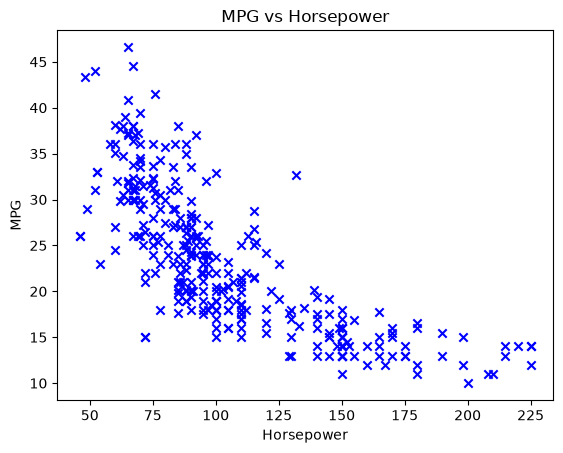

In [5]:
plt.scatter(x_train, y_train, marker='x', c='b') 
plt.title("MPG vs Horsepower")
plt.ylabel('MPG')
plt.xlabel('Horsepower')
plt.show()

## Implementation

#### Model function
- The model function for linear regression, which is a function that maps from `x` (Horsepower) to `y` (MPG) is represented as 
    $$f_{w,b}(x) = wx + b$$
    

- To train a linear regression model, you want to find the best $(w,b)$ parameters that fit your dataset.  

    - To compare how one choice of $(w,b)$ is better or worse than another choice, you can evaluate it with a cost function $J(w,b)$
      - $J$ is a function of $(w,b)$. That is, the value of the cost $J(w,b)$ depends on the value of $(w,b)$.
  
    - The choice of $(w,b)$ that fits your data the best is the one that has the smallest cost $J(w,b)$.


- To find the values $(w,b)$ that gets the smallest possible cost $J(w,b)$, you can use a method called **gradient descent**. 
  - With each step of gradient descent, your parameters $(w,b)$ come closer to the optimal values that will achieve the lowest cost $J(w,b)$.
  

- The trained linear regression model can then take the input feature $x$ and output a prediction $f_{w,b}(x)$.

Gradient descent involves repeated steps to adjust the value of your parameter $(w,b)$ to gradually get a smaller and smaller cost $J(w,b)$.

#### Cost function
The cost function for linear regression $J(w,b)$ is defined as

$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2$$ 

- $f_{w,b}(x^{(i)})$ is the model's prediction of MPG, as opposed to $y^{(i)}$, which is the actual MPG that is recorded in the data.
- $m$ is the number of training examples in the dataset

#### Model prediction

- For linear regression with one variable, the prediction of the model $f_{w,b}$ for an example $x^{(i)}$ is representented as:

$$ f_{w,b}(x^{(i)}) = wx^{(i)} + b$$

This is the equation for a line, with an intercept $b$ and a slope $w$

#### Gradient descent
The gradient descent algorithm is:

$$\begin{align*}& \text{repeat until convergence:} \; \lbrace \newline \; & \phantom {0000} b := b -  \alpha \frac{\partial J(w,b)}{\partial b} \newline       \; & \phantom {0000} w := w -  \alpha \frac{\partial J(w,b)}{\partial w}  \; & 
\newline & \rbrace\end{align*}$$

where, parameters $w, b$ are both updated simultaniously and where  
$$
\frac{\partial J(w,b)}{\partial b}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)}) 
$$
$$
\frac{\partial J(w,b)}{\partial w}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{w,b}(x^{(i)}) -y^{(i)})x^{(i)} 
$$
* m is the number of training examples in the dataset

    
*  $f_{w,b}(x^{(i)})$ is the model's prediction, while $y^{(i)}$, is the target value

### The Intuition of Cost
A scatter plot of car horsepower versus fuel efficiency (MPG). The solid line represents the model's straight-line prediction, while the vertical dashed lines (residuals) measure the exact distance between the prediction and real-world data points to calculate the overall cost.

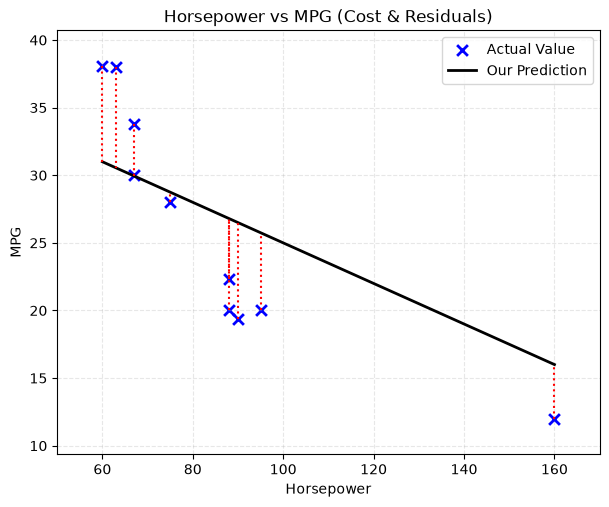

In [6]:
def plot_prediction_and_errors(x_train, y_train, w, b):
    # 1. Ensure data are flat 1D numpy arrays
    x_train = np.array(x_train).flatten()
    y_train = np.array(y_train).flatten()
    
    # 2. Calculate predictions: y = wx + b
    y_pred = (x_train * w) + b
    
    # 3. Find boundaries across actual and predicted data
    x_min, x_max = x_train.min(), x_train.max()
    y_min = min(y_train.min(), y_pred.min())
    y_max = max(y_train.max(), y_pred.max())
    
    # Calculate the total range (spread) of the data for scaling the padding
    x_range = x_max - x_min
    y_range = y_max - y_min
    
    # 4. Create the single plot
    fig, ax = plt.subplots(figsize=(7, 5.5))
    
    # Plot 1: Actual data points (Blue 'x' markers)
    ax.scatter(x_train, y_train, marker='x', c='blue', s=60, linewidth=2, label="Actual Value")
    
    # Plot 2: Prediction Line (Black continuous line)
    sort_idx = np.argsort(x_train)
    ax.plot(x_train[sort_idx], y_pred[sort_idx], c='k', linewidth=2, label="Our Prediction")
    
    # Plot 3: Vertical error lines (Red dotted lines tracking residuals)
    for i in range(len(x_train)):
        ax.vlines(x_train[i], y_train[i], y_pred[i], colors='red', linestyles='dotted', linewidth=1.5)
        
    # 5. DYNAMIC AXIS SCALING: Apply a clean 10% padding based on the data's range
    ax.set_xlim(x_min - (0.1 * x_range), x_max + (0.1 * x_range))
    ax.set_ylim(y_min - (0.1 * y_range), y_max + (0.1 * y_range))
    
    ax.set_title("Horsepower vs MPG (Cost & Residuals)")
    ax.set_xlabel("Horsepower")
    ax.set_ylabel("MPG")
    ax.legend()
    ax.grid(True, alpha=0.3, linestyle='--')

    #plt.savefig("horsepower_vs_mpg_cost.svg", format='svg', bbox_inches='tight')

    plt.show()

plot_prediction_and_errors(x_train[:10], y_train[:10], w=-0.15, b=40)      

### Implement the cost function `compute_cost`

* Iterate over the training examples, and for each example, compute:
    * The prediction of the model for that example $f_{wb}(x^{(i)}) =  wx^{(i)} + b $
    * The cost for that example  $cost^{(i)} =  (f_{wb} - y^{(i)})^2$
* Return the total cost over all examples $J(\mathbf{w},b) = \frac{1}{2m} \sum\limits_{i = 0}^{m-1} cost^{(i)}$ where $m$ is the number of training examples and $\sum$ is the summation operator

In [7]:
#Function to calculate the cost
def compute_cost(x, y, w, b):
   
    m = x.shape[0] 
    cost = 0
    
    for i in range(m):
        f_wb = w * x[i] + b
        cost = cost + (f_wb - y[i])**2
    total_cost = 1 / (2 * m) * cost

    return total_cost

### The cost curve
If we consider symmetric w and b, the cost curve is a bowl shape curve like below.

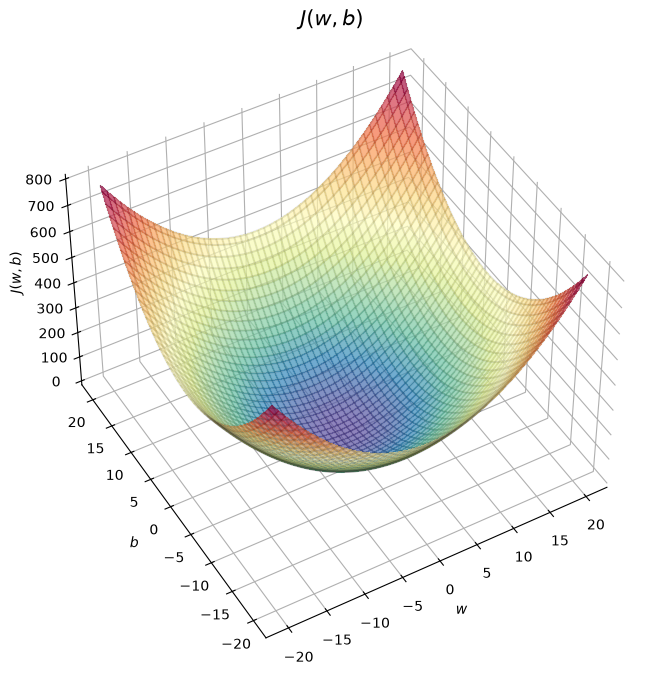

In [8]:
def soup_bowl():
    """ Create figure and plot with a 3D projection"""
    fig = plt.figure(figsize=(8,8))

    #Plot configuration
    ax = fig.add_subplot(111, projection='3d')
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_rotate_label(False)
    ax.view_init(45, -120)

    #Useful linearspaces to give values to the parameters w and b
    w = np.linspace(-20, 20, 100)
    b = np.linspace(-20, 20, 100)

    #Get the z value for a bowl-shaped cost function
    z=np.zeros((len(w), len(b)))
    j=0
    for x in w:
        i=0
        for y in b:
            z[i,j] = x**2 + y**2
            i+=1
        j+=1

    #Meshgrid used for plotting 3D functions
    W, B = np.meshgrid(w, b)

    #Create the 3D surface plot of the bowl-shaped cost function
    ax.plot_surface(W, B, z, cmap = "Spectral_r", alpha=0.7, antialiased=False)
    ax.plot_wireframe(W, B, z, color='k', alpha=0.1)
    ax.set_xlabel("$w$")
    ax.set_ylabel("$b$")
    ax.set_zlabel("$J(w,b)$", rotation=90)
    ax.set_title("$J(w,b)$", size=15)
    plt.show()

soup_bowl()

The cost curve with b fixed

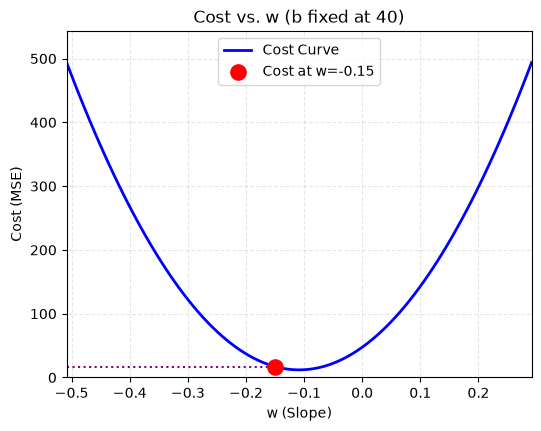

In [9]:
def plot_cost_curve(x_train, y_train, w, b):
    # 1. DYNAMIC VERTEX CENTERING
    w_minimum = np.sum((y_train - b) * x_train) / np.sum(x_train ** 2)
    
    # Define perfectly balanced window boundaries relative to the absolute minimum point
    w_min = w_minimum - 0.4
    w_max = w_minimum + 0.4
    w_array = np.linspace(w_min, w_max, 100)
    
    # 2. Calculate the cost at every point across the symmetric range
    cost_array = np.zeros_like(w_array)
    for i in range(len(w_array)):
        cost_array[i] = compute_cost(x_train, y_train, w_array[i], b)
        
    # 3. Calculate the cost for your custom chosen 'w' input coordinate
    cur_cost = compute_cost(x_train, y_train, w, b)
    
    # 4. Generate the plot
    fig, ax = plt.subplots(figsize=(6, 4.5))
    
    # Plot the smooth, perfectly centered cost parabola curve
    ax.plot(w_array, cost_array, color='blue', linewidth=2, label='Cost Curve')
    
    # Highlight your chosen active 'w' coordinate point
    ax.scatter(w, cur_cost, s=120, color='red', zorder=10, label=f"Cost at w={w:.2f}")
    
    # Guidelines pointing from the red dot to the axes boundaries
    ax.hlines(cur_cost, w_min, w, lw=1.5, color='purple', linestyle='dotted')
    
    # FIX: Explicitly target the first element [0] of the Y-limit tuple to avoid the ValueError
    ax.vlines(w, ax.get_ylim()[0], cur_cost, lw=1.5, color='purple', linestyle='dotted')
    
    # Dynamic styling boundaries
    ax.set_xlim(w_min, w_max)
    ax.set_ylim(0, cost_array.max() * 1.1)  
    
    # Titles and Labels
    ax.set_title(f"Cost vs. w (b fixed at {b})")
    ax.set_xlabel("w (Slope)")
    ax.set_ylabel("Cost (MSE)")
    ax.legend(loc='upper center')
    ax.grid(True, alpha=0.3, linestyle='--')

    plt.savefig("horsepower_vs_mpg_cost_curve.svg", format='svg', bbox_inches='tight')
    
    plt.show()

# Your dataset
x_data = np.array([86.0, 52.0, 84.0, 79.0, 82.0])          
y_data = np.array([27.0, 44.0, 32.0, 28.0, 31.0])

# Run execution block
plot_cost_curve(x_data, y_data, w=-0.15, b=40)


### Implement the gradient calculation `compute_gradient`

* Iterate over the training examples, and for each example, compute:
    * The prediction of the model for that example $f_{wb}(x^{(i)}) =  wx^{(i)} + b $
    * The gradient for the parameters $w, b$ from that example 
        $$
        \frac{\partial J(w,b)}{\partial b}^{(i)}  =  (f_{w,b}(x^{(i)}) - y^{(i)}) 
        $$
        $$
        \frac{\partial J(w,b)}{\partial w}^{(i)}  =  (f_{w,b}(x^{(i)}) -y^{(i)})x^{(i)} 
        $$
    

* Return the total gradient update from all the examples
    $$
    \frac{\partial J(w,b)}{\partial b}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} \frac{\partial J(w,b)}{\partial b}^{(i)}
    $$
    
    $$
    \frac{\partial J(w,b)}{\partial w}  = \frac{1}{m} \sum\limits_{i = 0}^{m-1} \frac{\partial J(w,b)}{\partial w}^{(i)} 
    $$
  where, $m$ is the number of training examples and $\sum$ is the summation operator

In [10]:
def compute_gradient(x, y, w, b): 
    """
    Computes the gradient for linear regression 
    Args:
      x (ndarray (m,)): Data, m examples 
      y (ndarray (m,)): target values
      w,b (scalar)    : model parameters  
    Returns
      dj_dw (scalar): The gradient of the cost w.r.t. the parameters w
      dj_db (scalar): The gradient of the cost w.r.t. the parameter b     
     """
    
    # Number of training examples
    m = x.shape[0]    
    dj_dw = 0
    dj_db = 0
    
    for i in range(m):  
        f_wb = w * x[i] + b 
        dj_dw_i = (f_wb - y[i]) * x[i] 
        dj_db_i = f_wb - y[i] 
        dj_db += dj_db_i
        dj_dw += dj_dw_i 
    dj_dw = dj_dw / m 
    dj_db = dj_db / m 
        
    return dj_dw, dj_db

### Implement the batch gradient descent 

In batch gradient descent batch refers to running all the examples in one iteration. A good way to verify that gradient descent is working correctly is to look at the value of $J(w,b)$ and check that it is decreasing with each step. If we take an appropriate value for the learning rate alpha, $J(w,b)$ should never increase and should converge to a steady value by the end of the algorithm.

In [11]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function): 
    """
    Performs gradient descent to fit w,b. Updates w,b by taking 
    num_iters gradient steps with learning rate alpha
    
    Args:
      x (ndarray (m,))  : Data, m examples 
      y (ndarray (m,))  : target values
      w_in,b_in (scalar): initial values of model parameters  
      alpha (float):     Learning rate
      num_iters (int):   number of iterations to run gradient descent
      cost_function:     function to call to produce cost
      gradient_function: function to call to produce gradient
      
    Returns:
      w (scalar): Updated value of parameter after running gradient descent
      b (scalar): Updated value of parameter after running gradient descent
      J_history (List): History of cost values
      p_history (list): History of parameters [w,b] 
      """
    
    w = copy.deepcopy(w_in) # avoid modifying global w_in
    # An array to store cost J and w's at each iteration primarily for graphing later
    J_history = []
    p_history = []
    b = b_in
    w = w_in
    
    for i in range(num_iters):
        # Calculate the gradient and update the parameters using gradient_function
        dj_dw, dj_db = gradient_function(x, y, w , b)     

        # Update Parameters using equation (3) above
        b = b - alpha * dj_db                            
        w = w - alpha * dj_dw                            

        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion 
            J_history.append( cost_function(x, y, w , b))
            p_history.append([w,b])
        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")
 
    return w, b, J_history, p_history #return w and J,w history for graphing

### Training
If you look at the Auto MPG dataset, horsepower values can range anywhere from 40 to 250, while MPG values typically sit between 10 and 45. If you feed those raw numbers directly into Gradient Descent, it will not converge. To avoid that, we scale the Horsepower data using the Standardization (Z-score Normalization) technique as shown below.
Now let's run the gradient descent algorithm above to learn the parameters for our dataset.

In [12]:
# Compute Mean and Standard Deviation
mu_x = np.mean(x_train)
sigma_x = np.std(x_train)

# Scale the input data
x_scaled = (x_train - mu_x) / sigma_x

#print(x_scaled)

# initialize parameters
w_init = 0
b_init = 0

# some gradient descent settings
iterations = 1000
tmp_alpha = 1.0e-2

# run gradient descent
w_final, b_final, J_hist, p_hist = gradient_descent(x_scaled ,y_train, w_init, b_init, tmp_alpha, iterations, compute_cost, compute_gradient)
print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration    0: Cost 2.96e+02  dj_dw:  5.899e+00, dj_db: -2.331e+01   w: -5.899e-02, b: 2.33105e-01
Iteration  100: Cost 5.03e+01  dj_dw:  2.159e+00, dj_db: -8.532e+00   w: -3.762e+00, b: 1.48634e+01
Iteration  200: Cost 1.75e+01  dj_dw:  7.904e-01, dj_db: -3.123e+00   w: -5.117e+00, b: 2.02186e+01
Iteration  300: Cost 1.31e+01  dj_dw:  2.893e-01, dj_db: -1.143e+00   w: -5.613e+00, b: 2.21788e+01
Iteration  400: Cost 1.25e+01  dj_dw:  1.059e-01, dj_db: -4.184e-01   w: -5.795e+00, b: 2.28963e+01
Iteration  500: Cost 1.24e+01  dj_dw:  3.876e-02, dj_db: -1.532e-01   w: -5.861e+00, b: 2.31589e+01
Iteration  600: Cost 1.24e+01  dj_dw:  1.419e-02, dj_db: -5.606e-02   w: -5.885e+00, b: 2.32550e+01
Iteration  700: Cost 1.24e+01  dj_dw:  5.193e-03, dj_db: -2.052e-02   w: -5.894e+00, b: 2.32902e+01
Iteration  800: Cost 1.24e+01  dj_dw:  1.901e-03, dj_db: -7.511e-03   w: -5.898e+00, b: 2.33031e+01
Iteration  900: Cost 1.24e+01  dj_dw:  6.958e-04, dj_db: -2.749e-03   w: -5.899e+00, b: 2.33078e+01


If we want to calculate the unscaled weight and the bias $w, b$, this is how we can derive it.

Our trained model uses the scaled feature:
$$\text{Prediction}=w_{\text{final}}\cdot x_{\text{scaled}}+b_{\text{final}}$$
We already know from our previous code that $$x_{\text{scaled}} = \frac{x_{\text{raw}} - \mu_x}{\sigma_x}$$ Let's plug that exact definition right into the model's equation:
$$\text{Prediction}=w_{\text{final}}\left(\frac{x_{\text{raw}}-\mu _{x}}{\sigma _{x}}\right)+b_{\text{final}}$$
Now, let's distribute the $w_{\text{final}}$ across the fraction:
$$\text{Prediction}=\left(\frac{w_{\text{final}}}{\sigma _{x}}\right)\cdot x_{\text{raw}}-\left(\frac{w_{\text{final}}\cdot \mu _{x}}{\sigma _{x}}\right)+b_{\text{final}}$$
Finally, let's group the terms so it matches our classic straight-line format $y = w \cdot x + b$:
$$\text{Prediction}=\underbrace{\left(\frac{w_{\text{final}}}{\sigma _{x}}\right)}_{\mathbf{w}_{\text{unscaled}}}\cdot \,x_{\text{raw}}+\underbrace{\left(b_{\text{final}}-\frac{w_{\text{final}}\cdot \mu _{x}}{\sigma _{x}}\right)}_{\mathbf{b}_{\text{unscaled}}}$$

In [13]:
w_unscaled = w_final / sigma_x
b_unscaled = b_final - (w_final * mu_x / sigma_x)

print(f"\nUnscaled Parameters for raw data:")
print(f"w_unscaled = {w_unscaled:.4f}")
print(f"b_unscaled = {b_unscaled:.4f}")


Unscaled Parameters for raw data:
w_unscaled = -0.1551
b_unscaled = 39.5746


### Plotting

#### Gradient

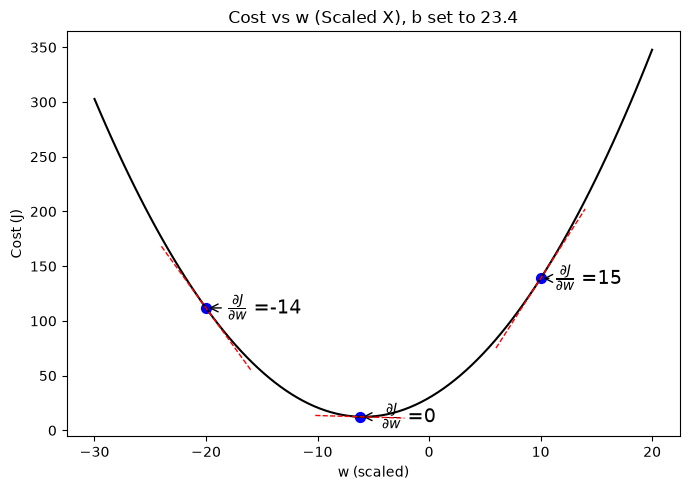

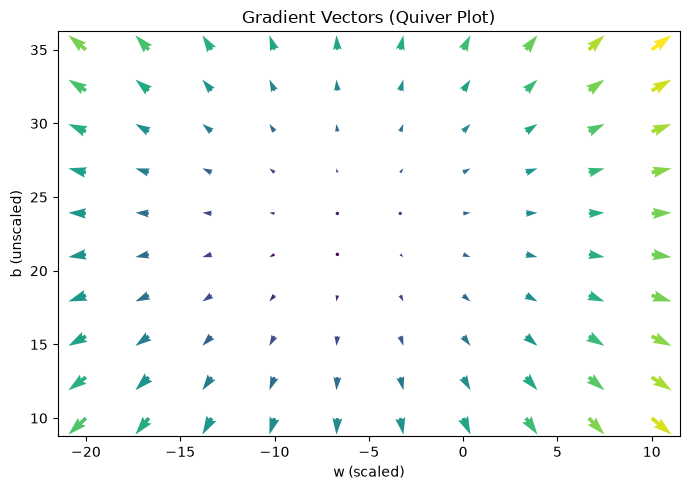

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def add_line(dj_dx, x1, y1, d, ax):
    x = np.linspace(x1-d, x1+d, 50)
    y = dj_dx*(x - x1) + y1
    ax.scatter(x1, y1, color="b", s=50)
    ax.plot(x, y, '--', c="r", zorder=10, linewidth=1)
    
    # Adjusted offset dynamically for scaled weight ranges
    xoff = 15 if x1 < 0 else 10
    ax.annotate(r"$\frac{\partial J}{\partial w}$ =%d" % dj_dx, fontsize=14,
                xy=(x1, y1), xycoords='data',
                xytext=(xoff, 10), textcoords='offset points',
                arrowprops=dict(arrowstyle="->"),
                horizontalalignment='left', verticalalignment='top')
    
def plt_gradients(x_scaled, y_train, f_compute_cost, f_compute_gradient):
    # =========================================================================
    # Diagram 1: Cost vs w (b fixed to 23.4)
    # =========================================================================
    fig1, ax1 = plt.subplots(figsize=(7, 5)) # Independent figure for the curve
    
    fix_b = 23.4
    w_array = np.linspace(-30, 20, 100)
    cost = np.zeros_like(w_array)

    for i in range(len(w_array)):
        tmp_w = w_array[i]
        cost[i] = f_compute_cost(x_scaled, y_train, tmp_w, fix_b)
        
    ax1.plot(w_array, cost, linewidth=1.5, color='black')
    ax1.set_title("Cost vs w (Scaled X), b set to 23.4", fontsize=12)
    ax1.set_ylabel('Cost (J)')
    ax1.set_xlabel('w (scaled)')

    # Plot tangent derivative lines at specific points along the curve
    for tmp_w in [-20, -6.2, 10]:
        dj_dw, dj_db = f_compute_gradient(x_scaled, y_train, tmp_w, fix_b)
        j = f_compute_cost(x_scaled, y_train, tmp_w, fix_b)
        add_line(dj_dw, tmp_w, j, 4, ax1) 

    plt.tight_layout()

    plt.savefig("gradient.svg", format='svg', bbox_inches='tight')
    
    plt.show() # Display the first complete diagram

    # =========================================================================
    # Diagram 2: Quiver Plot (Vector Field)
    # =========================================================================
    fig2, ax2 = plt.subplots(figsize=(7, 5)) # Independent figure for the quiver plot
    
    tmp_b, tmp_w = np.meshgrid(np.linspace(10, 35, 10), np.linspace(-20, 10, 10))
    U = np.zeros_like(tmp_w)
    V = np.zeros_like(tmp_b)
    
    for i in range(tmp_w.shape[0]):
        for j in range(tmp_w.shape[1]):
            U[i][j], V[i][j] = f_compute_gradient(x_scaled, y_train, tmp_w[i][j], tmp_b[i][j])
            
    X = tmp_w
    Y = tmp_b
    n = -2
    color_array = np.sqrt(((V-n)/2)**2 + ((U-n)/2)**2)

    ax2.set_title('Gradient Vectors (Quiver Plot)', fontsize=12)
    Q = ax2.quiver(X, Y, U, V, color_array, units='width', scale=500)
    ax2.set_xlabel("w (scaled)")
    ax2.set_ylabel("b (unscaled)")
    
    plt.tight_layout()
    plt.show() # Display the second complete diagram

plt_gradients(x_scaled, y_train, compute_cost, compute_gradient)


Above, the first plot shows $\frac{\partial J(w,b)}{\partial w}$ or the slope of the cost curve relative to $w$ at three points. On the right side of the plot, the derivative is positive, while on the left it is negative. Due to the `bowl shape`, the derivatives will always lead gradient descent toward the bottom where the gradient is zero. For this plot we have fixed $b=23.4$. 

Gradient descent will utilize both $\frac{\partial J(w,b)}{\partial w}$ and $\frac{\partial J(w,b)}{\partial b}$ to update parameters. The `quiver plot` (the second plot) provides a means of viewing the gradient of both parameters. The arrow sizes reflect the magnitude of the gradient at that point. The direction and slope of the arrow reflects the ratio of $\frac{\partial J(w,b)}{\partial w}$ and $\frac{\partial J(w,b)}{\partial b}$ at that point.
Note that the gradient points *away* from the minimum. Since the scaled gradient is *subtracted* from the current value of $w$ or $b$, this moves the parameter in a direction that will reduce cost.

#### Gradient Descent

#### Cost versus iterations of gradient descent 
A plot of cost versus iterations is a useful measure of progress in gradient descent. Cost should always decrease in successful runs.

`Note`: Since scaled data drops down to its lowest cost almost instantly (often by iteration 30), if your num_iters is set high (like 1,000), a standard plot will look like a sharp vertical drop followed by a long flat line. The added if statement automatically pinpoints the first 150 steps so you can actually see the beautiful curve of the descent.


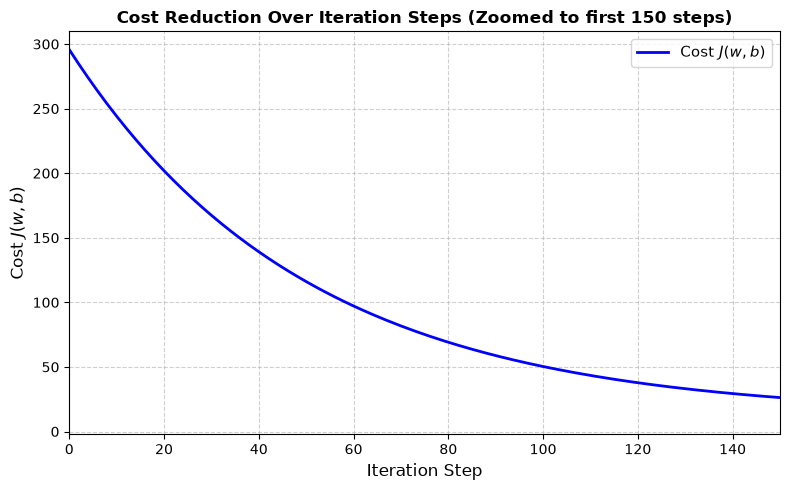

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the entire cost history (using J_history from your gradient_descent function)
ax.plot(J_hist, color='blue', linewidth=2, label='Cost $J(w,b)$')

# Style the chart
ax.set_title("Cost Reduction Over Iteration Steps (Scaled Features)", fontsize=14, fontweight='bold')
ax.set_xlabel("Iteration Step", fontsize=12)
ax.set_ylabel("Cost $J(w,b)$", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=11)

# Automatically zoom in horizontally if you ran many iterations, 
# since scaled data usually flatlines almost immediately.
if len(J_hist) > 200:
    ax.set_xlim(0, 150)
    ax.set_title("Cost Reduction Over Iteration Steps (Zoomed to first 150 steps)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


#### Contor plot
You can show the progress of gradient descent during its execution by plotting the cost over iterations on a contour plot of the cost(w,b).

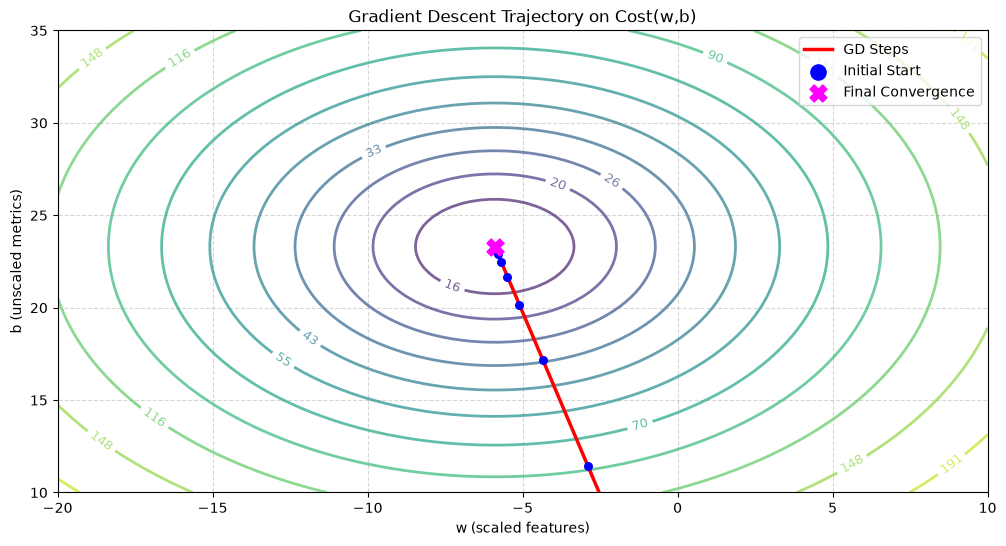

In [16]:
def plt_contour(x_scaled, y_train, p_hist, ax):
    """
    Plots the cost contour map of J(w,b)
    and overlays the trajectory path of your gradient descent history with visible cost values.
    """
    # 1. Setup exact bounds tailored around your scaled data parameters
    w_range = np.array([-20.0, 10.0])
    b_range = np.array([10.0, 35.0])
    
    w_space = np.linspace(*w_range, 100)
    b_space = np.linspace(*b_range, 100)

    # 2. mapping orientation: (b_space, w_space)
    tmp_b, tmp_w = np.meshgrid(b_space, w_space)
    z = np.zeros_like(tmp_b)
    m = x_scaled.shape[0]
    
    # Generate the exact cost boundary matrix values
    for i in range(tmp_w.shape[0]):
        for j in range(tmp_w.shape[1]):
            f_wb = tmp_w[i][j] * x_scaled + tmp_b[i][j]
            z[i, j] = (1 / (2 * m)) * np.sum((f_wb - y_train) ** 2)
            if z[i, j] == 0: 
                z[i, j] = 1e-6

    # 3. Plot the contours using logarithmic spacing to show structural steps
    CS = ax.contour(tmp_w, tmp_b, np.log(z), levels=12, linewidths=2, alpha=0.7)
    
    # np.exp(val) converts the log value back to the true original cost representation
    ax.clabel(CS, inline=True, fontsize=9, fmt=lambda val: f"{np.exp(val):.0f}")
    
    ax.set_title('Gradient Descent Trajectory on Cost(w,b)')
    ax.set_xlabel('w (scaled features)', fontsize=10)
    ax.set_ylabel('b (unscaled metrics)', fontsize=10)
    ax.set_xlim(w_range)
    ax.set_ylim(b_range)

    # 4. Correctly extract and overlay your actual gradient descent history coordinates
    p_hist_arr = np.array(p_hist)
    w_path = p_hist_arr[:, 0]
    b_path = p_hist_arr[:, 1]

    # Draw the main continuous path trajectory line
    ax.plot(w_path, b_path, color='red', linestyle='-', linewidth=2.5, zorder=5, label='GD Steps')
    
    # Scatter points along the path at regular intervals to visualize the step sizes shrinking
    step_interval = max(1, len(p_hist) // 15)
    ax.scatter(w_path[::step_interval], b_path[::step_interval], color='blue', marker='o', s=30, zorder=6)
    
    # Explicitly highlight the starting step position and the global minimum target reached
    ax.scatter(w_path[0], b_path[0], color='blue', marker='o', s=120, zorder=7, label='Initial Start')
    ax.scatter(w_path[-1], b_path[-1], color='magenta', marker='X', s=150, zorder=7, label='Final Convergence')
    
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)


fig, ax = plt.subplots(1, 1, figsize=(12, 6))

# Execute using your scaled data arrays and your parameter history array variable
plt_contour(x_scaled, y_train, p_hist, ax)

# Save high-quality vector graphic output
#fig.savefig("gradient_descent.svg", format="svg", bbox_inches="tight")

plt.show()


Above, the contour plot shows the $cost(w,b)$ over a range of $w$ and $b$. Cost levels are represented by the rings. Overlayed, using red arrows, is the path of gradient descent. Here are some things to note:
- The path makes steady (monotonic) progress toward its goal.
- initial steps are much larger than the steps near the goal.

### Predictions
Now that you have discovered the optimal values for the parameters $w$ and $b$, you can now use the model to predict MPG values based on our learned parameters.

In [17]:
def predict_mpg(raw_horsepower, w_scaled, b_scaled, mu_x, sigma_x):
    """
    Predicts the MPG for a given raw horsepower value using parameters 
    trained on Z-score scaled features.
    
    Args:
      raw_horsepower (float/ndarray): Unscaled horsepower value(s)
      w_scaled (scalar): Optimized weight from scaled gradient descent
      b_scaled (scalar): Optimized bias from scaled gradient descent
      mu_x (scalar): Mean of the training X data
      sigma_x (scalar): Standard deviation of the training X data
      
    Returns:
      predicted_mpg (float/ndarray): Predicted MPG value(s)
    """
    # 1. Scale the new input using the training statistics
    scaled_horsepower = (raw_horsepower - mu_x) / sigma_x
    
    # 2. Compute the linear regression formula: y = wx + b
    predicted_mpg = w_scaled * scaled_horsepower + b_scaled
    
    return predicted_mpg


In [18]:
print(f"MPG for 86 Horsepower is {predict_mpg(86, w_final, b_final, mu_x, sigma_x)}")
print(f"MPG for 52 Horsepower is {predict_mpg(52, w_final, b_final, mu_x, sigma_x)}")
print(f"MPG for 79 Horsepower is {predict_mpg(79, w_final, b_final, mu_x, sigma_x)}")

MPG for 86 Horsepower is 26.23611540017042
MPG for 52 Horsepower is 31.50945071466218
MPG for 79 Horsepower is 27.32180208256578


## Learning Rate

The larger $\alpha$ is, the faster gradient descent will converge to a solution. But, if it is too large, gradient descent will diverge. Above you have an example of a solution which converges nicely.

Let's try increasing the value of  $\alpha$ and see what happens:

In [19]:
# initialize parameters
w_init = 0
b_init = 0
# set alpha to a large value
iterations = 10
tmp_alpha = 3

# run gradient descent
w_final, b_final, J_hist, p_hist = gradient_descent(x_scaled ,y_train, w_init, b_init, tmp_alpha, iterations, compute_cost, compute_gradient)
print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration    0: Cost 1.17e+03  dj_dw:  5.899e+00, dj_db: -2.331e+01   w: -1.770e+01, b: 6.99315e+01
Iteration    1: Cost 4.64e+03  dj_dw: -1.180e+01, dj_db:  4.662e+01   w:  1.770e+01, b:-6.99315e+01
Iteration    2: Cost 1.85e+04  dj_dw:  2.360e+01, dj_db: -9.324e+01   w: -5.310e+01, b: 2.09795e+02
Iteration    3: Cost 7.40e+04  dj_dw: -4.720e+01, dj_db:  1.865e+02   w:  8.849e+01, b:-3.49658e+02
Iteration    4: Cost 2.96e+05  dj_dw:  9.439e+01, dj_db: -3.730e+02   w: -1.947e+02, b: 7.69247e+02
Iteration    5: Cost 1.18e+06  dj_dw: -1.888e+02, dj_db:  7.459e+02   w:  3.717e+02, b:-1.46856e+03
Iteration    6: Cost 4.74e+06  dj_dw:  3.776e+02, dj_db: -1.492e+03   w: -7.610e+02, b: 3.00706e+03
Iteration    7: Cost 1.89e+07  dj_dw: -7.551e+02, dj_db:  2.984e+03   w:  1.504e+03, b:-5.94418e+03
Iteration    8: Cost 7.58e+07  dj_dw:  1.510e+03, dj_db: -5.967e+03   w: -3.026e+03, b: 1.19583e+04
Iteration    9: Cost 3.03e+08  dj_dw: -3.021e+03, dj_db:  1.193e+04   w:  6.035e+03, b:-2.38467e+04


Above, $w$ and $b$ are bouncing back and forth between positive and negative with the absolute value increasing with each iteration. Further, each iteration $\frac{\partial J(w,b)}{\partial w}$ changes sign and cost is increasing rather than decreasing. This is a clear sign that the *learning rate is too large* and the solution is diverging.